# Dissociated scRNA-seq with a paired ST section

Dissociated cells have **no tissue coordinates**. DeltaTrace infers them from a paired spatial
transcriptomics (ST) section: map every cell onto the section's spots, then take the Earth
Mover's (1-Wasserstein) distance between two cells' spot distributions as their physical distance.

**map** (any probabilistic mapper; Tangram here) -> `pp.wasserstein` -> `pp.graphs` -> `tl.trajectory`

This is a template: point the two paths below at your own data and set the cluster names.

The outputs below come from the mouse liver pair of the DeltaTrace paper: hepatoblast scRNA-seq (Yang et al. 2017; 504 cells, labeled by embryonic day) on a Seq-Scope liver section (Cho et al. 2021).

In [1]:
import scanpy as sc

import deltatrace as dt

## Load

- `adata_sc`: the dissociated cells, **raw counts**, with a cluster / cell-type label in `obs`.
- `adata_st`: the paired ST section, raw counts, spot coordinates in `obsm["spatial"]`.

In [2]:
adata_sc = sc.read_h5ad("path/to/sc.h5ad")
adata_st = sc.read_h5ad("path/to/st.h5ad")

cluster_key = "cell_type"                  # column of adata_sc.obs holding the labels
sources = ["E10.5"]                        # where the trajectory starts
sinks = ["E17.5#hepatoblast/hepatocyte", "E17.5#cholangiocyte"]   # the terminal fates (see source-only below if unknown)
pxl_to_um = 1.0                            # ST coordinate units -> microns

## 1. Map cells to spots

DeltaTrace takes any probabilistic cell-to-spot mapping, it only needs an `AnnData` of shape `(n_cells, n_spots)` whose rows are distributions over `adata_st`'s spots (matched by spot name when both carry names). Already have one? Load it as `ad_map` and skip this cell.

Here we use [Tangram](https://doi.org/10.1038/s41592-021-01264-7), which is not a DeltaTrace dependency. Install it with `pip install tangram-sc "pandas<3"`: Tangram 1.0.4 does not run with pandas 3.

In [3]:
import warnings

with warnings.catch_warnings():   # importing tangram turns every warning off; this keeps them on
    import tangram as tg

sc_map, st_map = adata_sc.copy(), adata_st.copy()
sc.pp.normalize_total(sc_map)
sc.pp.normalize_total(st_map)
tg.pp_adatas(sc_map, st_map, genes=None)   # None: every shared gene; marker genes map better
ad_map = tg.map_cells_to_space(sc_map, st_map, device="cpu", random_state=42)   # "cuda:0" on a GPU

INFO:root:3529 training genes are saved in `uns``training_genes` of both single cell and spatial Anndatas.
INFO:root:3529 overlapped genes are saved in `uns``overlap_genes` of both single cell and spatial Anndatas.
INFO:root:uniform based density prior is calculated and saved in `obs``uniform_density` of the spatial Anndata.
INFO:root:rna count based density prior is calculated and saved in `obs``rna_count_based_density` of the spatial Anndata.
INFO:root:Allocate tensors for mapping.
INFO:root:Begin training with 3529 genes and rna_count_based density_prior in cells mode...
/path/to/site-packages/tangram/mapping_optimizer.py:61: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  self.d = torch.tensor(d, device=device, dtype=torch.float32)
INFO:root:Printing scores every 100 epochs.


Score: 0.246, KL reg: 0.002
Score: 0.370, KL reg: 0.000
Score: 0.371, KL reg: 0.000
Score: 0.371, KL reg: 0.000
Score: 0.371, KL reg: 0.000
Score: 0.371, KL reg: 0.000
Score: 0.371, KL reg: 0.000
Score: 0.371, KL reg: 0.000
Score: 0.371, KL reg: 0.000
Score: 0.371, KL reg: 0.000


INFO:root:Saving results..


## 2. Cell-cell spatial distance

The Earth Mover's distance between every pair of cells' spot distributions, over the spots'
Euclidean distances. `M` is the cell-to-spot mapping from step 1, `adata_sp` the section whose spot
coordinates give those distances, and `pxl_to_um` converts the coordinates to microns. Every pair is
solved, so this is the slow step on large datasets (`n_jobs=-1`, the default, uses every core).

In [4]:
adata_dist = dt.pp.wasserstein(
    M=ad_map,
    adata_sp=adata_st,
    pxl_to_um=pxl_to_um,
)

computing cell-cell Wasserstein distances ... finished (3 m 26 s)
done.


## 3. Expression graph + integration

Standard scanpy preprocessing; DeltaTrace reads the kNN graph `sc.pp.neighbors` leaves in the
object. `pp.graphs` then builds two graphs next to it: the spatially integrated graph `"intr"`, which
`tl.trajectory` uses, and the expression graph `"expr"`. UMAP is only for plotting.

In [5]:
sc.pp.normalize_total(adata_sc)
sc.pp.log1p(adata_sc)
sc.pp.highly_variable_genes(adata_sc, n_top_genes=2000)
sc.pp.pca(adata_sc)
sc.pp.neighbors(adata_sc)
sc.tl.umap(adata_sc)

ad_intg = dt.pp.graphs(
    adata_sc=adata_sc,
    adata_dist=adata_dist,
)

building the 'expr' graph ... finished (0.01 s)
building the 'intr' graph ... finished (0.01 s)
done.


## 4. Trajectory and lineages

One call samples source and sink cells, solves the transport for pseudotime and flow, builds
the velocity field (on the UMAP here: dissociated cells have no tissue coordinates) and assigns
every cell a fate.

sampling source and sink endpoints ... finished (0.01 s)
solving quadratically regularized transport ... finished (0.02 s)
building the velocity grid ... finished (0.00 s)
assigning lineages by absorbing chain ... finished (0.00 s)
done.


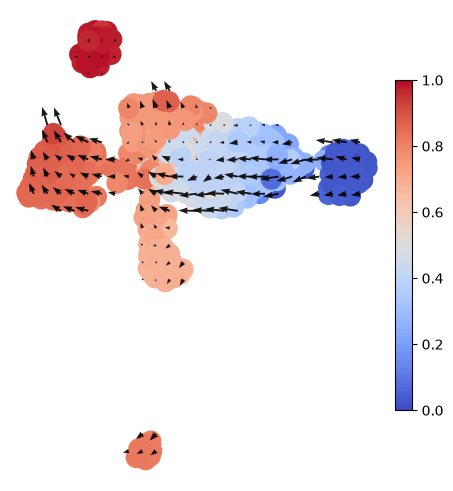

In [6]:
dt.tl.trajectory(
    adata=ad_intg,
    source_clusters=sources,
    sink_clusters=sinks,
    cluster_key=cluster_key,
)

dt.pl.pseudotime(adata=ad_intg)

Each cell's fate is in `obs["lineage"]`, with `obs["lineage_confidence"]` and a
`fate_<lineage>` probability per fate. Cells the flow never carries to a declared sink are
`"unassigned"` (drawn gray).

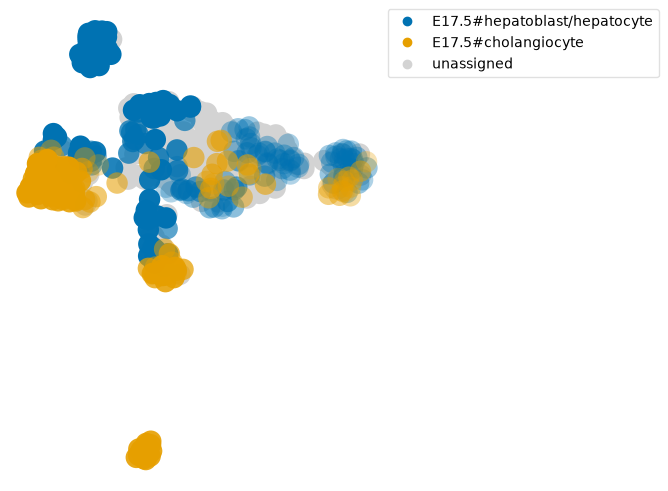

lineage
unassigned                      193
E17.5#hepatoblast/hepatocyte    185
E17.5#cholangiocyte             126
Name: count, dtype: int64

In [7]:
dt.pl.lineages(adata=ad_intg)
ad_intg.obs["lineage"].value_counts()

The same flow, summarized between clusters:

abstracting the flow into a cluster graph ... finished (0.01 s)
done.


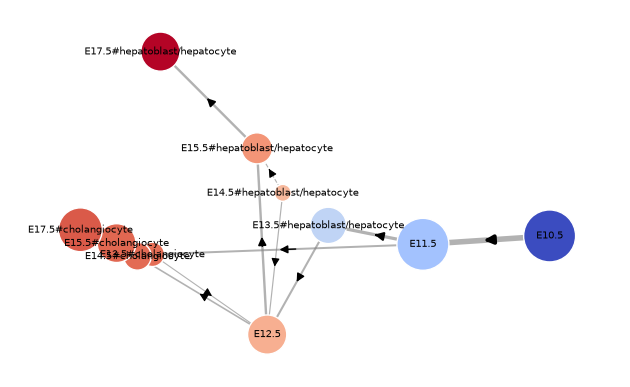

In [8]:
dt.tl.cluster_trajectory(
    adata=ad_intg,
    cluster_key=cluster_key,
)
dt.pl.cluster_trajectory(
    adata=ad_intg,
    cluster_key=cluster_key,
)

## 5. Source-only: when the terminal fates are unknown

With `sink_clusters=None`, every non-source cell absorbs the flow, and `trajectory` prints how
terminal each cluster ends up (`term_score = 1 - flow_out/flow_in`) instead of assigning lineages: you
pick the fates. `key_added` keeps this run next to the one above in the same object.

Source-only is for *finding* the fates: once you know them, pass them as `sinks` as in step 4,
which gives the better trajectory.

In [9]:
run = "source_only"
res = dt.tl.trajectory(
    adata=ad_intg,
    source_clusters=sources,
    sink_clusters=None,
    cluster_key=cluster_key,
    key_added=run,
)
res["terminality"]

sampling source and sink endpoints ... finished (0.00 s)
solving quadratically regularized transport ... finished (0.02 s)
building the velocity grid ... finished (0.00 s)
cluster terminality (term_score = 1 - flow_out/flow_in, higher = more terminal):
                              flow_in  flow_out  absorbed  term_score
E17.5#hepatoblast/hepatocyte   0.1079    0.0000    0.1079      1.0000
E17.5#cholangiocyte            0.1285    0.0397    0.0889      0.6915
E14.5#hepatoblast/hepatocyte   0.0895    0.0387    0.0508      0.5673
E15.5#cholangiocyte            0.2224    0.1240    0.0984      0.4426
E15.5#hepatoblast/hepatocyte   0.1945    0.1152    0.0794      0.4080
E12.5                          0.9993    0.7262    0.2730      0.2732
E14.5#cholangiocyte            0.1661    0.1281    0.0381      0.2293
E13.5#cholangiocyte            0.1571    0.1349    0.0222      0.1415
E11.5                          1.3384    1.1670    0.1714      0.1281
E13.5#hepatoblast/hepatocyte   0.5893    0.5195

/tmp/ipykernel_1590867/2843857432.py:2: UserWarning: Source-only run: no lineages assigned. Rerun with sink_clusters=['E17.5#hepatoblast/hepatocyte'], or call dt.tl.lineages(adata=adata, source_clusters=['E10.5'], cluster_key='cell_type', n_lineages=1, key_added='source_only') on this flow.
  res = dt.tl.trajectory(


,flow_in,flow_out,absorbed,term_score
E17.5#hepatoblast/hepatocyte,0.107937,0.000000,0.107937,1.000000
E17.5#cholangiocyte,0.128539,0.039650,0.088889,0.691531
E14.5#hepatoblast/hepatocyte,0.089539,0.038745,0.050794,0.567281
E15.5#cholangiocyte,0.222371,0.123958,0.098413,0.442561
E15.5#hepatoblast/hepatocyte,0.194526,0.115161,0.079365,0.407991
E12.5,0.999256,0.726241,0.273016,0.273219
E14.5#cholangiocyte,0.166146,0.128051,0.038095,0.229288
E13.5#cholangiocyte,0.157098,0.134876,0.022222,0.141454
E11.5,1.338402,1.166973,0.171429,0.128085
E13.5#hepatoblast/hepatocyte,0.589342,0.519501,0.069841,0.118507


assigning lineages by absorbing chain ... finished (0.01 s)
done.


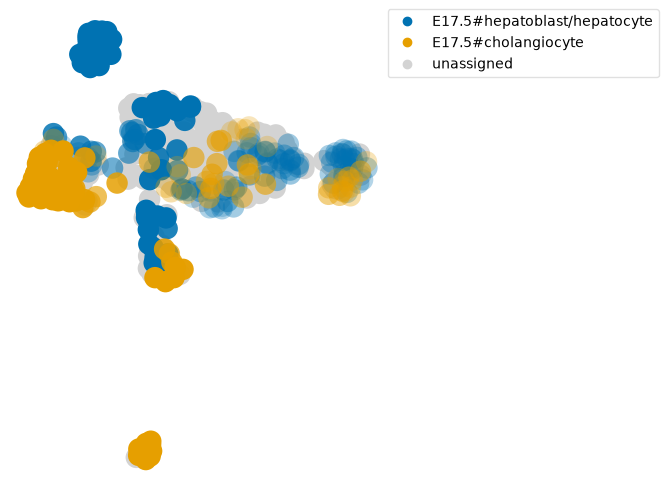

In [10]:
# lineages on this run's flow: the two E17.5 clusters top the ranking, so cut at two
dt.tl.lineages(
    adata=ad_intg,
    source_clusters=sources,
    cluster_key=cluster_key,
    n_lineages=2,
    key_added=run,
)
dt.pl.lineages(
    adata=ad_intg,
    key_added=run,
)